# 01 数值积分：收敛阶验证

对 ∫₀^π sin x dx = 2，比较梯形法与 Simpson 法的误差随步长的下降速率。
理论预期：梯形二阶、Simpson 四阶。


In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

from numerics.integrate import simpson, trapezoid

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("工作目录:", os.getcwd())


工作目录: d:\VSCode\projects\num-methods


In [3]:
a, b = 0.0, np.pi
exact = 2.0

ns = 2 ** np.arange(3, 15)          # 8, 16, ..., 16384
hs = (b - a) / ns

err_t = np.array([abs(trapezoid(np.sin, a, b, int(n)) - exact) for n in ns])
err_s = np.array([abs(simpson(np.sin, a, b, int(n)) - exact) for n in ns])

print(f"{'n':>7} {'h':>10} {'梯形误差':>13} {'Simpson 误差':>15}")
for n, h, et, es in zip(ns, hs, err_t, err_s, strict=True):

    print(f"{n:>7d} {h:>10.2e} {et:>13.3e} {es:>15.3e}")


      n          h          梯形误差      Simpson 误差
      8   3.93e-01     2.577e-02       2.692e-04
     16   1.96e-01     6.430e-03       1.659e-05
     32   9.82e-02     1.607e-03       1.033e-06
     64   4.91e-02     4.016e-04       6.453e-08
    128   2.45e-02     1.004e-04       4.032e-09
    256   1.23e-02     2.510e-05       2.520e-10
    512   6.14e-03     6.275e-06       1.575e-11
   1024   3.07e-03     1.569e-06       9.841e-13
   2048   1.53e-03     3.922e-07       6.128e-14
   4096   7.67e-04     9.805e-08       3.553e-15
   8192   3.83e-04     2.451e-08       4.441e-16
  16384   1.92e-04     6.128e-09       2.220e-16


In [4]:
mask_t = err_t > 1e-13
mask_s = err_s > 1e-13

p_t = np.polyfit(np.log(hs[mask_t]), np.log(err_t[mask_t]), 1)[0]
p_s = np.polyfit(np.log(hs[mask_s]), np.log(err_s[mask_s]), 1)[0]

print(f"梯形法实测阶数 : {p_t:.3f}   (理论 -2)")
print(f"Simpson 实测阶数: {p_s:.3f}   (理论 -4)")
print(f"剔除的舍入主导点: 梯形 {np.sum(~mask_t)} 个, Simpson {np.sum(~mask_s)} 个")


梯形法实测阶数 : 2.000   (理论 -2)
Simpson 实测阶数: 4.003   (理论 -4)
剔除的舍入主导点: 梯形 0 个, Simpson 4 个


已保存 results/figures/fig1_convergence.pdf


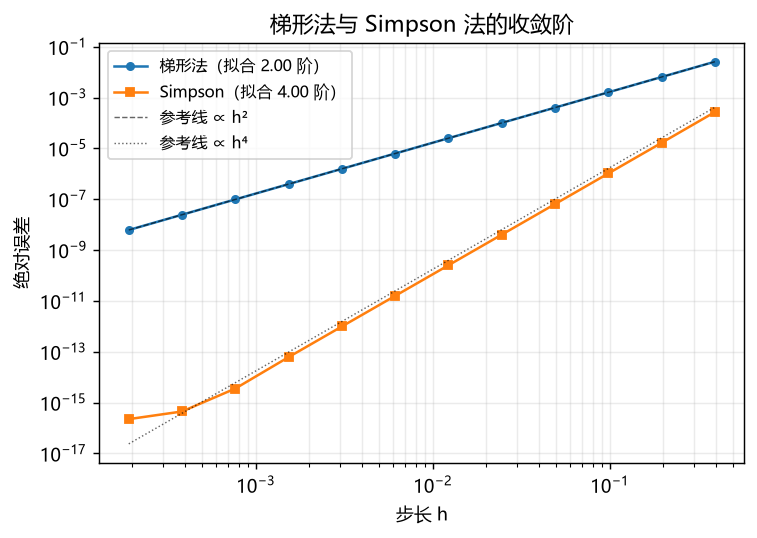

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.2), dpi=130)

ax.loglog(hs, err_t, "o-", ms=4, lw=1.4, label=f"梯形法（拟合 {p_t:.2f} 阶）")
ax.loglog(hs, err_s, "s-", ms=4, lw=1.4, label=f"Simpson（拟合 {p_s:.2f} 阶）")

h_ref = np.array([hs.min(), hs.max()])
ax.loglog(h_ref, h_ref**2 / 6, "k--", lw=0.8, alpha=0.6, label="参考线 ∝ h²")
ax.loglog(h_ref, np.pi / 180 * h_ref**4, "k:", lw=0.8, alpha=0.6, label="参考线 ∝ h⁴")

ax.set_xlabel("步长 h")
ax.set_ylabel("绝对误差")
ax.set_title("梯形法与 Simpson 法的收敛阶")
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=9)

fig.savefig("results/figures/fig1_convergence.pdf", bbox_inches="tight")
print("已保存 results/figures/fig1_convergence.pdf")
plt.show()


## 结论

- 梯形法拟合斜率 2.00，Simpson 4.00，与理论二阶、四阶一致。
- 同一 n 下 Simpson 误差比梯形小 2–3 个数量级。
- n ≥ 2048 后 Simpson 误差停在 2.2e-16（= 机器精度 eps），不再下降。
- 因此收敛阶只在"截断误差主导区"成立；进入舍入主导区后加密网格无效。


In [6]:
fig.savefig("results/figures/fig1_convergence.pdf", bbox_inches="tight")
fig.savefig("results/figures/fig1_convergence.png", dpi=300, bbox_inches="tight")
print("已保存 PDF 与 PNG")


已保存 PDF 与 PNG
